# ICS5111 · Session 02: setup notebook
## Prepare: before Tuesday 27 October

This notebook takes about 30 to 40 minutes. It does three things before the session:

1. it installs the course library and downloads Cora, so that the walkthrough opens without delay on Tuesday;
2. it lets you check yourself on the seven Session 01 measures that the first hour recaps, so that you arrive knowing which one you want explained;
3. it introduces Cora, the citation graph used in the second half, and one random walk, the starting point of graph embeddings.

Run the cells from the top, in order. Where a cell asks for a prediction, write it **before** running the check: a wrong prediction is useful, because it tells you what to ask on Tuesday. Nothing here is assessed.

## S0 · Setup

The next two cells install the course library, `ai-learning-kit`, and start Session 02. The library holds the session's helper functions (`T`), the reference results and the code that downloads Cora from its publisher, LINQS, the first time it is needed. Nothing has to be downloaded or uploaded by hand, and the walkthrough and practice notebooks use the same library.

| Where you work | What to do |
|---|---|
| Notebook Tutor | Run both cells. The tutor already includes the library, so it skips the first one. |
| Colab | Run both cells; the install takes about a minute. If Colab warns that the notebook was not written by Google, choose *Run anyway*. |
| Jupyter on your own computer | Run both cells, in an environment with Python 3.10 or later. |

If the second cell cannot download Cora (no internet, or the publisher's site is down), its message says what to do. No GPU or API key is needed. If a cell cannot run, the saved outputs in the notebook still show the expected result.

In [ ]:
%pip install -q "ai-learning-kit[graphs]@https://github.com/charlieabela/ai-learning-kit/archive/refs/tags/v0.5.0.zip"

In [2]:
import ai_learning_kit as kit
kit.start("ICS5111", "S02")       # also downloads Cora from LINQS the first time
T = kit.tools()                   # the Session 02 helper functions

import numpy as np, pandas as pd, networkx as nx, matplotlib.pyplot as plt
from IPython.display import display
import json, platform
SEED = T.SEED
print("helpers", T.VERSION, "| Python", platform.python_version(), "| numpy", np.__version__, "| networkx", nx.__version__)

ai-learning-kit 0.5.0 · ICS5111 S02: Graph embeddings
Data: Cora citation network (LINQS), checked (kit.datasets.status() shows where it is kept)
Helpers: T = kit.tools(). This session has no answer book: the notebook checks itself.
helpers 2026-10-27 | Python 3.12.3 | numpy 2.5.4 | networkx 3.7


## S1 · Session 01 self-check on the seven-node graph

The first hour of Tuesday's session recaps Parts 2 and 3 of the Session 01 walkthrough. The six items below use the seven-node graph from Session 01: two triangles, {1, 2, 3} and {5, 6, 7}, joined through node 4. For each item, write your prediction in the `my_answer` cell (replace `None`), then run the check. The check prints whether your prediction matches and where to revisit the topic: a section of the Session 01 walkthrough and the slides of the 83-slide Session 01 deck on the VLE. If you leave `None`, the check simply shows the answer.

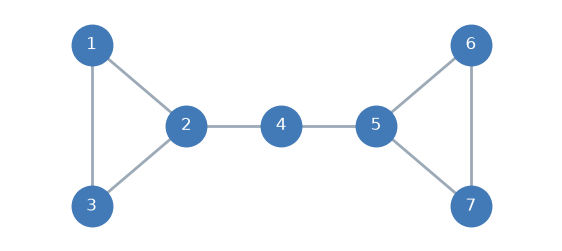

In [3]:
toy = T.toy_graph()          # the seven-node graph of Session 01
T.draw_toy(); plt.show()

def report(item, ok, truth, revisit):
    """Print the outcome of one self-check item."""
    if ok is None:
        print(f"{item}: no prediction entered.")
    else:
        print(f"{item}: your prediction {'matches' if ok else 'differs'}.")
    print("   answer:", truth)
    print("   revisit:", revisit)

### Item 1 · Degree distribution

The degree distribution $p_k$ is the fraction of nodes with exactly $k$ neighbours. Write it as a dictionary from degree to fraction, for example `{1: 0.5, 4: 0.5}`.

In [4]:
my_answer = None   # e.g. {2: ..., 3: ...}

In [5]:
degrees = dict(toy.degree())
truth = {k: list(degrees.values()).count(k) / toy.number_of_nodes() for k in sorted(set(degrees.values()))}
ok = None if my_answer is None else (set(my_answer) == set(truth) and all(abs(my_answer[k] - truth[k]) < 0.01 for k in truth))
report("Item 1", ok, {k: round(v, 3) for k, v in truth.items()}, "walkthrough 2a; slides 51–52")

Item 1: no prediction entered.
   answer: {2: 0.714, 3: 0.286}
   revisit: walkthrough 2a; slides 51–52


Five of the seven nodes have degree 2 and two (nodes 2 and 5) have degree 3, so $p_2 = 5/7$ and $p_3 = 2/7$. The mean degree is $2m/n = 16/7 \approx 2.29$. On a graph this small every degree is close to the mean; S2 below shows a real graph where it is not.

### Item 2 · Hop distances from node 1

Breadth-first search from node 1 explores the graph layer by layer. Write the hop distance from node 1 to every node as a dictionary, for example `{1: 0, 2: 1, ...}`.

In [6]:
my_answer = None   # e.g. {1: 0, 2: ..., 3: ..., 4: ..., 5: ..., 6: ..., 7: ...}

In [7]:
truth = dict(sorted(nx.single_source_shortest_path_length(toy, 1).items()))
ok = None if my_answer is None else (dict(my_answer) == truth)
report("Item 2", ok, truth, "walkthrough 2b; slides 54–57")
print("   eccentricity of node 1:", max(truth.values()), "| diameter of the graph:", nx.diameter(toy))

Item 2: no prediction entered.
   answer: {1: 0, 2: 1, 3: 1, 4: 2, 5: 3, 6: 4, 7: 4}
   revisit: walkthrough 2b; slides 54–57
   eccentricity of node 1: 4 | diameter of the graph: 4


The layers are {2, 3} at distance 1, {4} at 2, {5} at 3 and {6, 7} at 4. Node 1 is a corner of the graph: its eccentricity, the distance to the farthest node, equals the diameter, 4.

### Item 3 · Components after removing an edge

Suppose the edge between nodes 2 and 4 is deleted. How many connected components does the graph then have? Write a whole number.

In [8]:
my_answer = None   # a whole number

In [9]:
cut = toy.copy(); cut.remove_edge(2, 4)
parts = [sorted(c) for c in nx.connected_components(cut)]
truth = len(parts)
ok = None if my_answer is None else (int(my_answer) == truth)
report("Item 3", ok, f"{truth} components: {parts}", "walkthrough 2c–2d; slides 60–62")

Item 3: no prediction entered.
   answer: 2 components: [[1, 2, 3], [4, 5, 6, 7]]
   revisit: walkthrough 2c–2d; slides 60–62


Edge 2–4 is a bridge: it lies on every path between the two triangles, so deleting it leaves {1, 2, 3} and {4, 5, 6, 7}. Deleting edge 2–3 instead would leave one component, because 2 and 3 are still joined through node 1.

### Item 4 · Local clustering of node 2 and transitivity

The local clustering coefficient of a node is the fraction of pairs of its neighbours that are themselves linked. Transitivity is three times the number of triangles divided by the number of connected triples in the whole graph. Write a pair `(clustering of node 2, transitivity)`, rounded to three decimals.

In [10]:
my_answer = None   # e.g. (0.5, 0.4)

In [11]:
truth = (round(nx.clustering(toy, 2), 3), round(nx.transitivity(toy), 3))
ok = None if my_answer is None else all(abs(a - b) < 0.01 for a, b in zip(my_answer, truth))
report("Item 4", ok, truth, "walkthrough 2e–2f; slides 64–65")
print("   average clustering:", round(nx.average_clustering(toy), 3))

Item 4: no prediction entered.
   answer: (0.333, 0.545)
   revisit: walkthrough 2e–2f; slides 64–65
   average clustering: 0.667


Node 2 has neighbours 1, 3 and 4, which form three pairs; only 1–3 is linked, so $C_2 = 1/3$. The graph has 2 triangles and 11 connected triples, so transitivity is $3 \times 2 / 11 = 6/11 \approx 0.545$, while the average of the local coefficients is 0.667. The two summaries weight nodes differently, which is why a report should say which one it uses.

### Item 5 · Which node has the highest betweenness?

Betweenness counts the shortest paths between other pairs of nodes that pass through a node. Which node has the highest betweenness? Write its number, then think about why degree centrality would not pick it.

In [12]:
my_answer = None   # a node number

In [13]:
bet = nx.betweenness_centrality(toy, normalized=False)
truth = max(bet, key=bet.get)
ok = None if my_answer is None else (int(my_answer) == truth)
report("Item 5", ok, f"node {truth}", "walkthrough 3a; slides 67–70")
display(pd.DataFrame({"degree": dict(toy.degree()), "betweenness (pairs)": bet}).T)

Item 5: no prediction entered.
   answer: node 4
   revisit: walkthrough 3a; slides 67–70


,1,2,3,4,5,6,7
degree,2.0,3.0,2.0,2.0,3.0,2.0,2.0
betweenness (pairs),0.0,8.0,0.0,9.0,8.0,0.0,0.0


Node 4 lies on all $3 \times 3 = 9$ shortest paths between {1, 2, 3} and {5, 6, 7}, more than nodes 2 and 5 (8 each), yet its degree is only 2, the same as the corners. Degree counts direct ties; betweenness measures brokerage, a position between groups.

### Item 6 · PageRank

PageRank is the long-run share of time a random surfer spends at each node, with teleportation (damping 0.85). Which nodes score highest? Write a set of node numbers, for example `{1, 7}`. Then answer in words, in the markdown cell below: what problem does teleportation fix on a *directed* graph?

In [14]:
my_answer = None   # a set of node numbers

In [15]:
pr = nx.pagerank(toy, alpha=0.85)
top = max(pr.values())
truth = {n for n, v in pr.items() if abs(v - top) < 1e-9}
ok = None if my_answer is None else (set(my_answer) == truth)
report("Item 6", ok, f"nodes {sorted(truth)}", "walkthrough 3a–3c; slides 72–75")
print("   PageRank:", {n: round(v, 3) for n, v in sorted(pr.items())}, "| sum:", round(sum(pr.values()), 6))

Item 6: no prediction entered.
   answer: nodes [2, 5]
   revisit: walkthrough 3a–3c; slides 72–75
   PageRank: {1: 0.127, 2: 0.183, 3: 0.127, 4: 0.125, 5: 0.183, 6: 0.127, 7: 0.127} | sum: 1.0


**Your answer on teleportation:** …

Nodes 2 and 5 score highest (0.183): on an undirected graph PageRank is close to proportional to degree. Node 4, the broker of Item 5, scores lowest (0.125). Teleportation matters on directed graphs: a *dead end* (no outgoing edge) leaks the surfer's probability, and a *spider trap* (a group with no edge out) absorbs it. Jumping to a random node with probability 0.15 repairs both.

### Before you move on

Write down the one concept you want explained on Tuesday: the item where your prediction differed, or the one you got right without being sure why.

**My concept for Tuesday:** …

## S2 · Cora at a glance

The second half of Tuesday's session uses Cora, a citation graph of machine-learning papers. Each node is a paper, each edge a citation (treated as undirected), and each paper has one of seven topic labels and 1,433 binary word features. The session splits the papers once into 541 for training, 541 for validation and 1,626 for test. Run the cell and note what a node, an edge, a feature and a label are here.

In [16]:
G, X, y, paper_ids, classes, split = T.load_cora()
print("papers (nodes):", G.number_of_nodes(), "| citations (edges):", G.number_of_edges())
print("word features per paper:", X.shape[1], "| topics:", len(classes))
print("split: train", len(split["train"]), "| validation", len(split["val"]), "| test", len(split["test"]))
display(pd.Series(np.bincount(y), index=[c.replace("_", " ") for c in classes], name="papers per topic"))

papers (nodes): 2708 | citations (edges): 5278
word features per paper: 1433 | topics: 7
split: train 541 | validation 541 | test 1626


Case Based                298
Genetic Algorithms        418
Neural Networks           818
Probabilistic Methods     426
Reinforcement Learning    217
Rule Learning             180
Theory                    351
Name: papers per topic, dtype: int64

**Predict before running:** Item 1 computed the degree distribution of a tiny graph in which every degree was close to the mean. Will Cora's degrees also stay close to their mean, or will a few papers be cited far more than the rest?

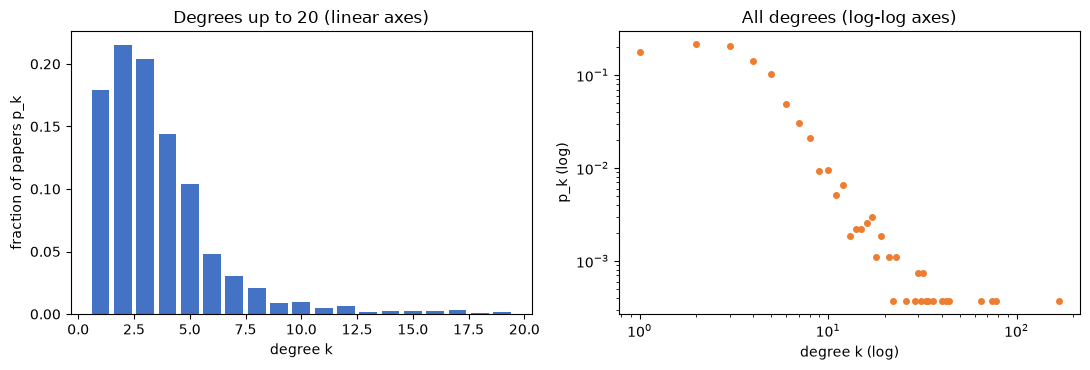

mean degree 3.90 | median 3 | variance 27.3 | maximum 168
papers with degree 1: 485 | papers with degree 20 or more: 24


In [17]:
deg = np.array([d for _, d in G.degree()])
values, counts = np.unique(deg, return_counts=True)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].bar(values[values <= 20], counts[values <= 20] / len(deg), color="#4472C4")
axs[0].set(xlabel="degree k", ylabel="fraction of papers p_k", title="Degrees up to 20 (linear axes)")
axs[1].loglog(values, counts / len(deg), "o", color="#ED7D31", ms=4)
axs[1].set(xlabel="degree k (log)", ylabel="p_k (log)", title="All degrees (log-log axes)")
plt.tight_layout(); plt.show()
print(f"mean degree {deg.mean():.2f} | median {np.median(deg):.0f} | variance {deg.var():.1f} | maximum {deg.max()}")
print(f"papers with degree 1: {(deg == 1).sum()} | papers with degree 20 or more: {(deg >= 20).sum()}")

**Reading the output.** The mean degree is 3.90 but the median is 3, the variance (27.3) is about seven times the mean, and one paper has 168 citation links. On log-log axes the points fall roughly along a downward line over two orders of magnitude: a **heavy tail**, as in the preferential-attachment graphs of Session 01 (slide 52), and unlike the Poisson degrees of a random graph. As in Item 1, the mean alone is a poor summary here. Keep this picture in mind on Tuesday: random walks visit high-degree papers often, and that affects the training data of DeepWalk.

## S3 · One random walk on the seven-node graph

A random walk starts at a node and moves, at every step, to a neighbour chosen uniformly at random. On Tuesday, walks like this one become the training data for node vectors. The cell samples one walk of six positions starting at node 1, using the session's helper and seed, and prints the probability of every step.

walk: [1, 3, 2, 3, 1, 2]
  at 1: neighbours [2, 3], moved to 3 with probability 1/2
  at 3: neighbours [1, 2], moved to 2 with probability 1/2
  at 2: neighbours [1, 3, 4], moved to 3 with probability 1/3
  at 3: neighbours [1, 2], moved to 1 with probability 1/2
  at 1: neighbours [2, 3], moved to 2 with probability 1/2
probability of this walk, given that it starts at 1: 0.0208 (= 1/48)


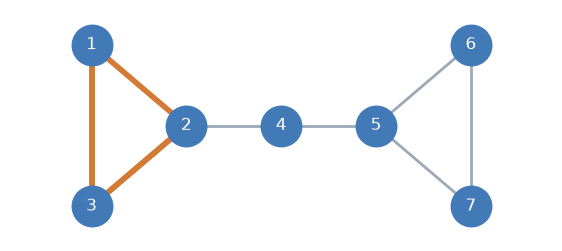

In [18]:
walk = [w for w in T.walks(toy, n_walks=1, length=6, seed=SEED) if w[0] == 1][0]
print("walk:", walk)
probability = 1.0
for a, b in zip(walk, walk[1:]):
    neighbours = sorted(toy.neighbors(a))
    step = 1 / len(neighbours)
    probability *= step
    print(f"  at {a}: neighbours {neighbours}, moved to {b} with probability 1/{len(neighbours)}")
print(f"probability of this walk, given that it starts at 1: {probability:.4f} (= 1/{round(1 / probability)})")
T.draw_toy(highlight=walk); plt.show()

Read as a sentence, the walk is cut into (centre, context) pairs by a sliding window: every node is paired with the nodes up to `window` positions before and after it. Positions count, not graph distance, and a node that is visited twice is paired twice.

In [19]:
for window in (1, 2):
    pairs = T.context_pairs([walk], window=window)
    print(f"window {window}: {len(pairs)} pairs ->", [tuple(map(int, p)) for p in pairs])

window 1: 10 pairs -> [(1, 3), (3, 1), (3, 2), (2, 3), (2, 3), (3, 2), (3, 1), (1, 3), (1, 2), (2, 1)]
window 2: 18 pairs -> [(1, 3), (1, 2), (3, 1), (3, 2), (3, 3), (2, 1), (2, 3), (2, 3), (2, 1), (3, 3), (3, 2), (3, 1), (3, 2), (1, 2), (1, 3), (1, 2), (2, 3), (2, 1)]


**Question to answer in a sentence:** why could this walk occur, and what is its probability? (Hint: the walk returns to nodes it has visited; is that allowed, and why does it matter for the pairs?)

**My explanation:** …

The walk 1, 3, 2, 3, 1, 2 stays inside the left triangle and revisits nodes, which a random walk is allowed to do. Each step is a uniform choice among the neighbours of the current node, so the probability is $\frac12 \cdot \frac12 \cdot \frac13 \cdot \frac12 \cdot \frac12 = \frac{1}{48}$. Window 1 gives 10 pairs and window 2 gives 18. Pairs such as (3, 2) occur more than once, and with window 2 node 3 is even paired with itself, (3, 3), because it returns within two positions. Nodes that share many windows will be placed close together by the embedding; nodes 5, 6 and 7 never appear here, which is why DeepWalk starts many walks from every node.

## S4 · What to bring on Tuesday

- The one Session 01 concept you want explained (end of S1).
- Your explanation of the walk in S3.
- Any question you were unsure about in the pre-quiz.
- A laptop with Notebook Tutor installed, or with Colab access. The walkthrough uses the same library and data, so there is nothing more to download or upload.

If a cell failed, post the section, the cell and the error text in the VLE students' forum before Tuesday.